In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, PowerTransformer
from scipy.stats import boxcox
# import warnings
# warnings.filterwarnings('ignore')


In [95]:
df = pd.read_csv("/Users/mac/Downloads/datasettttt.csv")
df

,Customer_ID,Age,Gender,Income,Education_Level,Marital_Status,Years_with_Company,Satisfaction_Score,Purchased
0,1,56.0,Other,108652.0,High School,Widowed,26.0,6.687898,No
1,2,69.0,Other,132755.0,PhD,Single,25.0,1.858344,No
2,3,NaN,Other,76985.0,NaN,Widowed,29.0,1.933107,Yes
3,4,32.0,Male,70069.0,NaN,Widowed,24.0,1.437919,Yes
4,5,60.0,Other,NaN,NaN,NaN,11.0,6.229136,No
...,...,...,...,...,...,...,...,...,...
995,996,60.0,Male,27099.0,High School,Divorced,1.0,3.907897,No
996,997,NaN,Male,138614.0,Master,Widowed,29.0,9.889746,No
997,998,62.0,Male,45431.0,PhD,Widowed,16.0,3.931163,Yes
998,999,35.0,Female,76492.0,NaN,Widowed,8.0,4.547224,Yes


In [96]:
df.shape

(1000, 9)

In [97]:
df.describe()

,Customer_ID,Age,Income,Years_with_Company,Satisfaction_Score
count,1000.000000,850.000000,850.000000,1000.000,850.000000
mean,500.500000,43.721176,86691.327059,14.940,5.495345
std,288.819436,14.948160,37787.622723,8.753,2.601818
min,1.000000,18.000000,20163.000000,0.000,1.001679
25%,250.750000,31.000000,52417.250000,7.000,3.245225
50%,500.500000,43.000000,86042.500000,16.000,5.552657
75%,750.250000,56.000000,119948.000000,22.250,7.822599
max,1000.000000,69.000000,149992.000000,29.000,9.978605


## Checking Outliers

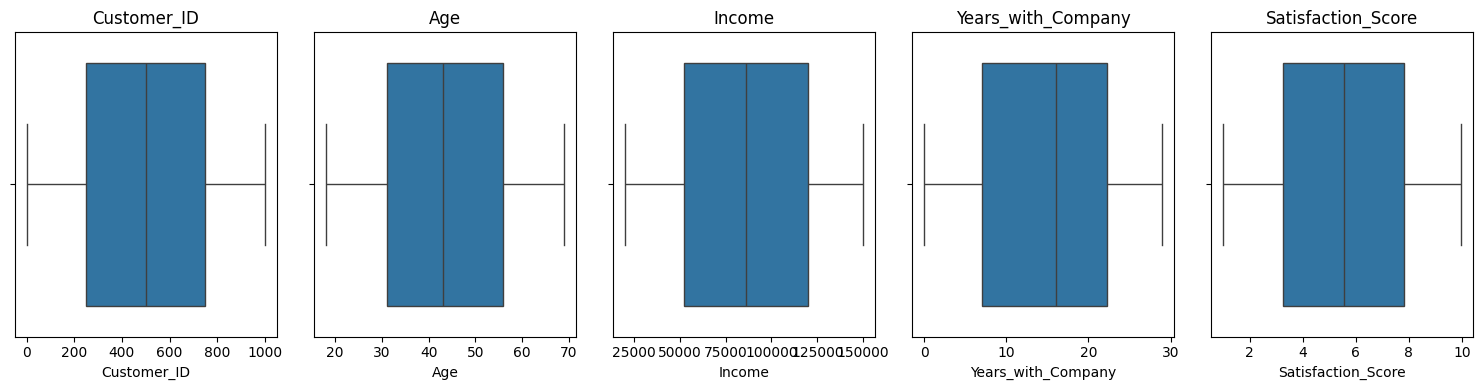

In [98]:
# --- BEFORE: Boxplots (visual) ---
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
plt.figure(figsize=(max(6, len(num_cols)*3), 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, len(num_cols), i)
    sns.boxplot(x=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()


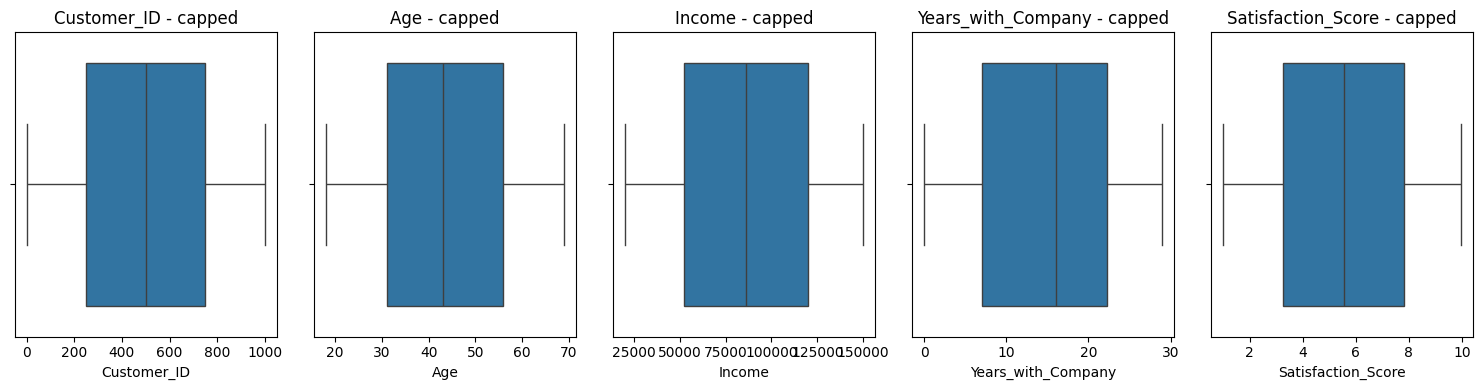

In [99]:
# Cap outliers using IQR (in-place)
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lb = Q1 - 1.5 * IQR
    ub = Q3 + 1.5 * IQR
    df[col] = np.where(df[col] < lb, lb, np.where(df[col] > ub, ub, df[col]))

# --- AFTER: Boxplots (capped) ---
plt.figure(figsize=(max(6, len(num_cols)*3), 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, len(num_cols), i)
    sns.boxplot(x=df[col])
    plt.title(f'{col} - capped')
plt.tight_layout()
plt.show()


## Check skewness in numerical columns and apply Box-cox

🔹 Skewness before transformation:
Customer_ID           0.000000
Age                  -0.035554
Income               -0.001631
Years_with_Company   -0.092026
Satisfaction_Score   -0.015544
dtype: float64

🔹 Skewness after Box-Cox / Yeo-Johnson (where applied):
Customer_ID          -0.288423
Age                  -0.120917
Income               -0.154993
Years_with_Company   -0.284628
Satisfaction_Score   -0.182042
dtype: float64


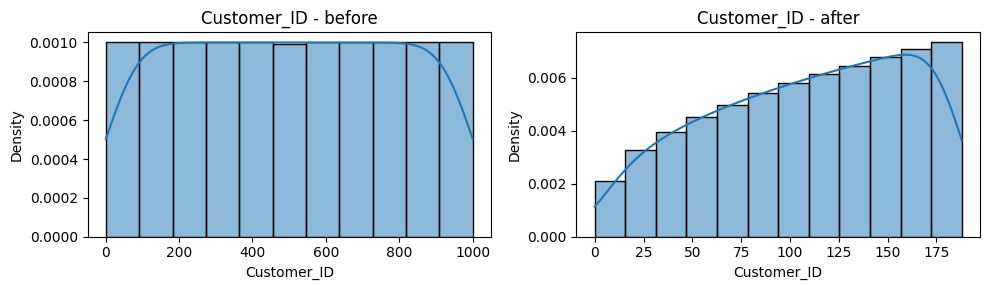

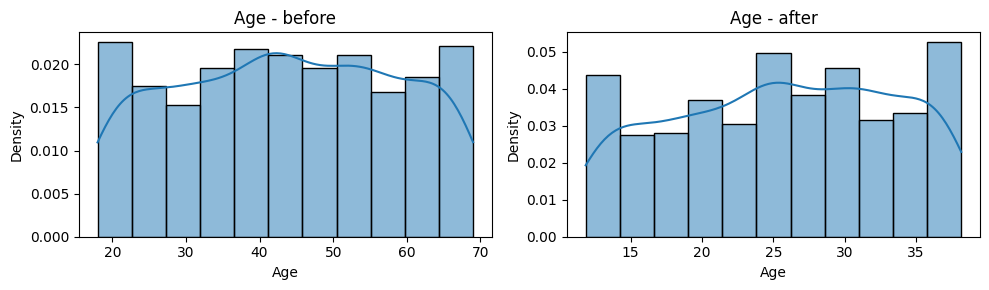

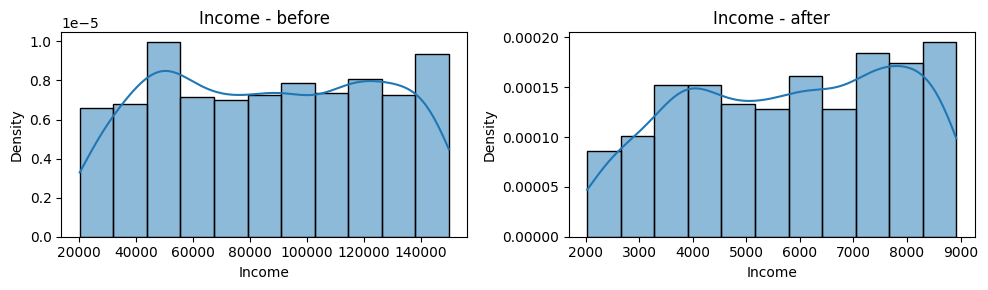

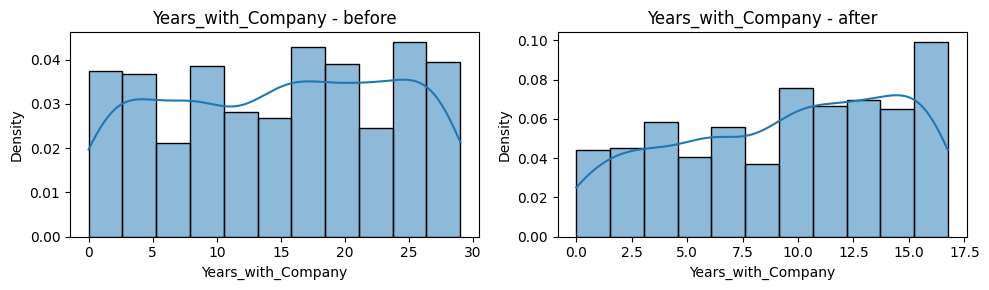

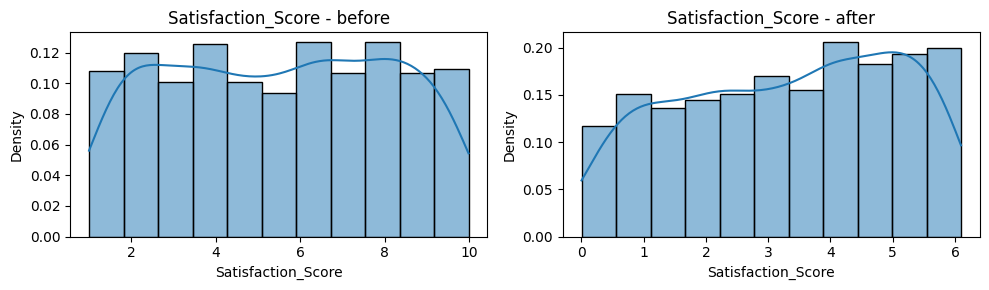

In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
orig = df[num_cols].copy()
print(" Skewness before transformation:")
print(orig.skew())

# Apply Box-Cox for strictly positive numeric columns, else Yeo-Johnson (PowerTransformer)
from sklearn.preprocessing import PowerTransformer
for col in num_cols:
    ser = df[col]
    non_na = ser.dropna()
    if non_na.empty or non_na.nunique() <= 1:
        continue
    if (non_na > 0).all():
        transformed, lam = boxcox(non_na.values)
    else:
        pt = PowerTransformer(method='yeo-johnson', standardize=False)
        transformed = pt.fit_transform(non_na.values.reshape(-1,1)).flatten()
    df.loc[non_na.index, col] = transformed

print("\n Skewness after Box-Cox / Yeo-Johnson (where applied):")
print(df[num_cols].skew())

# Plot before vs after distributions
for col in num_cols:
    plt.figure(figsize=(10,3))
    plt.subplot(1,2,1)
    sns.histplot(orig[col].dropna(), kde=True, stat='density')
    plt.title(f'{col} - before')
    plt.subplot(1,2,2)
    sns.histplot(df[col].dropna(), kde=True, stat='density')
    plt.title(f'{col} - after')
    plt.tight_layout()
    plt.show()


## Performing Bivariate analysis

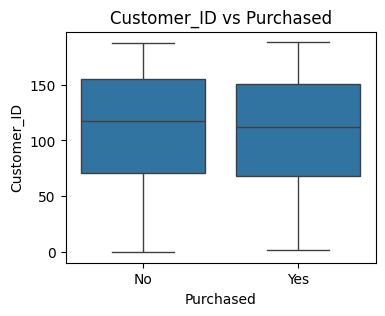

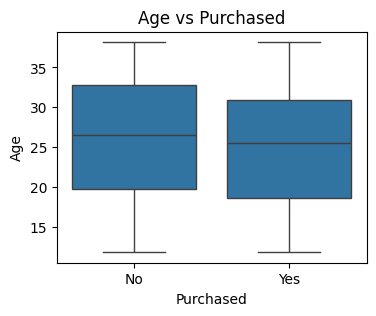

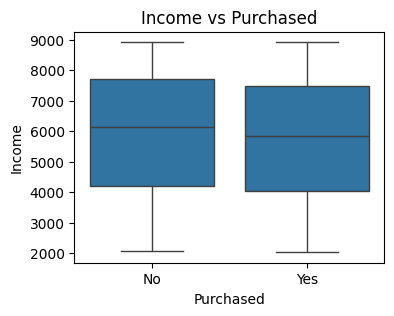

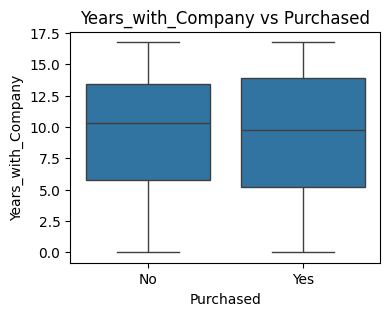

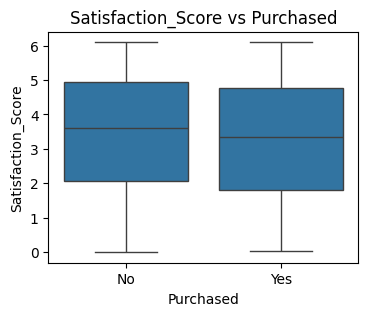

Purchased,No,Yes
Education_Level,,
Bachelor,0.478673,0.521327
High School,0.450000,0.550000
Master,0.509709,0.490291
PhD,0.502146,0.497854


Purchased,No,Yes
Marital_Status,,
Divorced,0.454976,0.545024
Married,0.445596,0.554404
Single,0.481013,0.518987
Widowed,0.511962,0.488038


Purchased,No,Yes
Gender,,
Female,0.469512,0.530488
Male,0.488372,0.511628
Other,0.478659,0.521341


In [101]:
# Bivariate analysis: numeric vs Purchased (boxplots) and categorical crosstabs
if 'Purchased' in df.columns:
    for col in df.select_dtypes(include=[np.number]).columns:
        plt.figure(figsize=(4,3))
        sns.boxplot(x=df['Purchased'], y=df[col])
        plt.title(f'{col} vs Purchased')
        plt.show()
    for col in ['Education_Level','Marital_Status','Gender']:
        if col in df.columns:
            display(pd.crosstab(df[col], df['Purchased'], normalize='index'))


## Remove non-usable variables

In [102]:
# Remove non-usable variables
if 'Customer_ID' in df.columns:
    df.drop('Customer_ID', axis=1, inplace=True)
# Drop any columns with a single unique value (not useful)
for col in df.columns.tolist():
    if df[col].nunique() <= 1:
        df.drop(col, axis=1, inplace=True)
print('Dropped non-usable columns. Remaining columns count:', len(df.columns))


Dropped non-usable columns. Remaining columns count: 8


##  Encode categorical columns using LabelEncoder

In [106]:
# Handle missing values first (merged here so encoding runs on cleaned data)
for c in ['Education_Level','Marital_Status','Purchased']:
    if c in df.columns:
        df[c] = df[c].fillna(df[c].mode().iloc[0])
if 'Income' in df.columns: df['Income'] = df['Income'].fillna(df['Income'].median())
if 'Age' in df.columns: df['Age'] = df['Age'].fillna(df['Age'].mean())
if 'Satisfaction_Score' in df.columns: df['Satisfaction_Score'] = df['Satisfaction_Score'].fillna(df['Satisfaction_Score'].median())

cat_cols = df.select_dtypes(include=['object']).columns.tolist()

# Frequency-encode categorical values
for col in cat_cols:
    freq_map = df[col].value_counts().to_dict()
    df[f'{col}_freq'] = df[col].map(freq_map).fillna(0).astype(float)

# Keep a label-encoded version for modeling convenience
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

print('\n Categorical columns frequency-encoded and label-encoded.')



 Categorical columns frequency-encoded and label-encoded.


## Print df.info

In [104]:
# Final df.info()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   1000 non-null   float64
 1   Gender                1000 non-null   int64  
 2   Income                1000 non-null   float64
 3   Education_Level       1000 non-null   int64  
 4   Marital_Status        1000 non-null   int64  
 5   Years_with_Company    1000 non-null   float64
 6   Satisfaction_Score    1000 non-null   float64
 7   Purchased             1000 non-null   int64  
 8   Gender_freq           1000 non-null   float64
 9   Education_Level_freq  1000 non-null   float64
 10  Marital_Status_freq   1000 non-null   float64
 11  Purchased_freq        1000 non-null   float64
dtypes: float64(8), int64(4)
memory usage: 93.9 KB


## Print correlation matrix

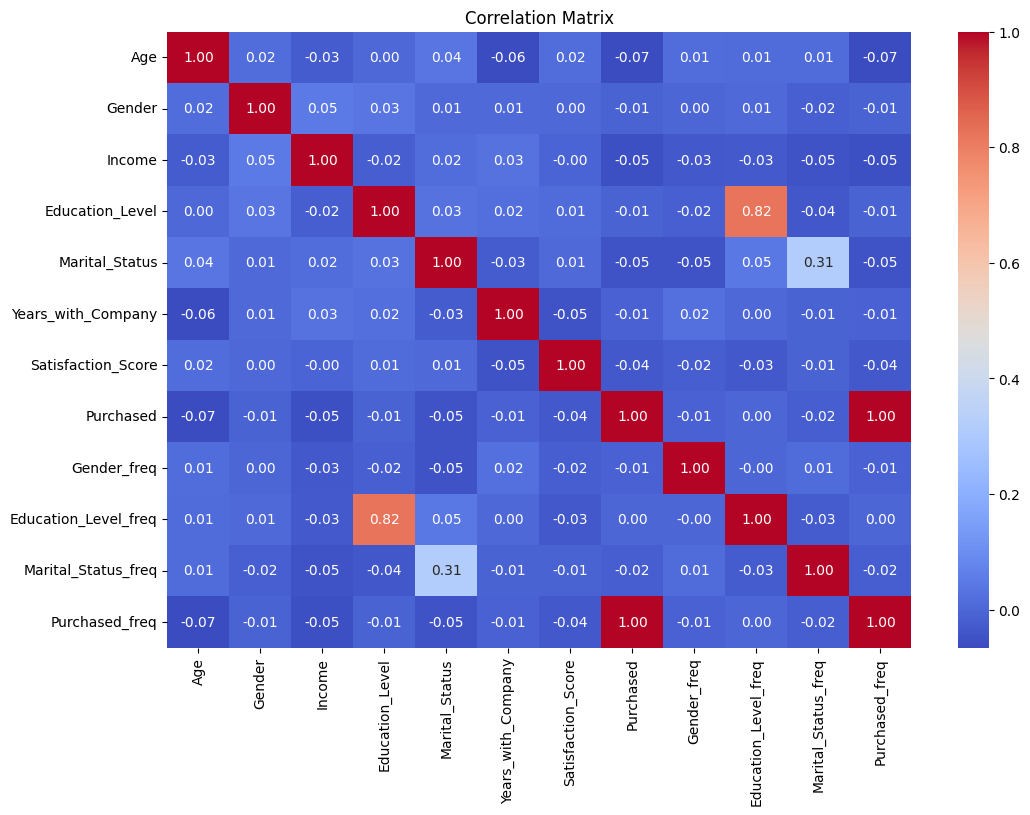

In [105]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()